# Robusta–chicory regression, 0–50 % chicory — nested leave-one-session-out

**Data:** pure robusta (RB100, 0 %) and the ten robusta–chicory blends from 5 to 50 % chicory, across the three
acquisition sessions. Nothing else: no arabica, no pure chicory, no unknowns.

**One training method for every model:**

1. **Pool** all three sessions into one calibration set, so the model sees session-to-session variation.
2. **Outer loop — leave-one-session-out.** Hold out one whole session, train on the other two, predict the
   held-out one. Repeat for all three. This produces the reported error.
3. **Inner loop — tuning without the held-out session.** Inside each outer fold, the model's hyperparameter
   (latent variables for PLSR, alpha for Ridge, and so on) is chosen by leave-one-concentration-out on the
   training sessions only, using the one-standard-error rule: the simplest setting whose error is within one
   standard error of the best.
4. **Preprocessing inside the fold.** The outlier-trimming model is refitted on the training sessions in every
   outer fold, so the held-out session never shapes its own preprocessing.
5. **Pick the method** with the lowest mean error over the three held-out sessions.
6. **Final model** — the selected method, tuned the same way on all three sessions, refitted on everything and
   saved.

Section 9 explains why this suits data taken in separate acquisitions. Outputs go to `final_regression/`.

## 1. Setup

In [1]:
import os
import json, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import Ridge, ElasticNet, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# ------------------------------- EDIT -------------------------------
BASE    = Path(os.environ.get("COFFEE_DATA", "../.."))
OLD_CSV = BASE / "samples_out" / "training_samples.csv"     # sessions 1 and 2
NEW_CSV = BASE / "batch3_out"  / "training_samples.csv"     # session 3
OUT     = BASE / "final_regression"
LEVELS_KEEP = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]     # % chicory: RB100 + 5-50 %
WL_MIN, WL_MAX = 1000.0, 2450.0
TRIM_PCT, K_UNIT = 10, 8          # trimming and super-patch size, as in the existing pipeline
N_BOOT = 2000
# ---------------------------------------------------------------------

OUT.mkdir(exist_ok=True, parents=True)
RNG = np.random.default_rng(0)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S_COLOR  = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}   # one colour and one marker per session
S_MARKER = {1: "o", 2: "s", 3: "^"}
HIGHLIGHT, OTHER = "#2a78d6", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
})
BANDS = [(1450, "O–H water"), (1730, "C–H lipid"), (1940, "O–H water"),
         (2100, "C–O carbohydrate"), (2310, "C–H combination")]

## 2. Data — RB100 and 5–50 % only

In [2]:
old = pd.read_csv(OLD_CSV)
new = pd.read_csv(NEW_CSV)
for c in ("scan", "group", "plate"):
    new[c] = new[c].astype(str) + "_b3"        # keep session-3 plate ids distinct
DATA = pd.concat([old, new], ignore_index=True)
DATA = DATA[DATA.species.isin(["robusta", "robusta_chicory"])
            & (DATA.role == "calibration")
            & DATA.chicory_pct.isin(LEVELS_KEEP)].reset_index(drop=True)
DATA["session"] = DATA["day"].astype(int)
assert sorted(DATA.chicory_pct.unique()) == LEVELS_KEEP, sorted(DATA.chicory_pct.unique())

wc = [c for c in DATA.columns if c.replace(".", "", 1).isdigit()]
wl_all = np.array([float(c) for c in wc])
BM = (wl_all >= WL_MIN) & (wl_all <= WL_MAX)
WL, COLS = wl_all[BM], [c for c, k in zip(wc, BM) if k]

def preprocess(R):
    # absorbance, then remove each spectrum's own offset: a multiplicative brightness change
    # between acquisitions becomes an additive constant in log space and is subtracted away
    R = np.clip(np.asarray(R, float), 1e-3, None)
    Z = np.log10(1.0 / R)
    return Z - Z.mean(-1, keepdims=True)

Z       = preprocess(DATA[COLS].values)
SESSION = DATA["session"].to_numpy()
GROUP   = DATA["group"].astype(str).to_numpy()
Y       = DATA["chicory_pct"].to_numpy(float)

print(f"{len(DATA)} patches | {DATA.group.nunique()} plates | {len(WL)} bands ({WL[0]:.0f}-{WL[-1]:.0f} nm)")
print(DATA.groupby(["session", "label"]).agg(chicory=("chicory_pct", "first"), plates=("group", "nunique"),
                                             patches=("sample_id", "size")).to_string())

4910 patches | 33 plates | 266 bands (1001-2446 nm)
                   chicory  plates  patches
session label                              
1       RB100          0.0       3      410
2       RB[50:50]     50.0       3      450
        RB[60:40]     40.0       3      450
        RB[70:30]     30.0       3      450
        RB[80:20]     20.0       3      450
        RB[90:10]     10.0       3      450
3       RB[55:45]     45.0       3      450
        RB[65:35]     35.0       3      450
        RB[75:25]     25.0       3      450
        RB[85:15]     15.0       3      450
        RB[95:5]       5.0       3      450


## 3. Building blocks

- `units()` — trims the worst 10 % of patches within each plate (trimming model fitted on the given sessions
  only) and averages the rest into spatially contiguous super-patches of about 8 patches.
- `GRIDS` — the hyperparameter tried for each method, **ordered from simplest to most complex**, because the
  one-standard-error rule picks the first setting that is good enough.
- `tune()` — the inner loop: leave-one-concentration-out on the training data, scored per plate.

In [3]:
META = ["session", "capture", "label", "group", "chicory_pct", "patch_row", "patch_col"]
_UNITS = {}

def units(train_sessions, k=K_UNIT):
    key = tuple(sorted(train_sessions))
    if key in _UNITS:
        return _UNITS[key]
    tr = np.isin(SESSION, key)
    ref = PLSRegression(n_components=4).fit(Z[tr], Y[tr])
    mu = Z[tr].mean(0)
    T = (Z - mu) @ ref.x_rotations_
    q = np.sum(((Z - mu) - T @ ref.x_loadings_.T) ** 2, axis=1)
    keep = pd.Series(q).groupby(GROUP).rank(pct=True).to_numpy() <= 1 - TRIM_PCT / 100
    idx = []
    for g in pd.unique(GROUP):
        ii = np.where((GROUP == g) & keep)[0]
        if len(ii) < k:
            continue
        n = max(1, len(ii) // k)
        lab = KMeans(n_clusters=n, n_init=5, random_state=0).fit_predict(
            DATA.loc[ii, ["patch_row", "patch_col"]].to_numpy(float))
        idx += [ii[lab == c] for c in range(n) if (lab == c).any()]
    ZU = np.array([Z[i].mean(0) for i in idx])
    UM = DATA.iloc[[i[0] for i in idx]][META].reset_index(drop=True)
    _UNITS[key] = (ZU, UM)
    return ZU, UM

def make(name, prm):
    if name == "PLSR":              return PLSRegression(n_components=prm)
    if name == "PCR":               return make_pipeline(PCA(n_components=prm), LinearRegression())
    if name == "Ridge":             return make_pipeline(StandardScaler(), Ridge(alpha=prm))
    if name == "ElasticNet":        return make_pipeline(StandardScaler(), ElasticNet(alpha=prm, l1_ratio=.5, max_iter=10000))
    if name == "SVR (linear)":      return make_pipeline(StandardScaler(), SVR(kernel="linear", C=prm))
    if name == "SVR (RBF)":         return make_pipeline(StandardScaler(), SVR(kernel="rbf", C=prm, gamma="scale"))
    if name == "Random Forest":     return RandomForestRegressor(n_estimators=200, min_samples_leaf=prm, max_features=.33,
                                                                 random_state=0, n_jobs=-1)
    if name == "Gradient Boosting": return GradientBoostingRegressor(n_estimators=prm, learning_rate=.05, max_depth=3,
                                                                     subsample=.8, random_state=0)
    raise KeyError(name)

GRIDS = {    # simplest -> most complex
    "PLSR":              list(range(1, 13)),
    "PCR":               [1, 2, 3, 4, 5, 6, 8, 10, 12, 15],
    "Ridge":             [1000, 300, 100, 30, 10, 3, 1, .3, .1],
    "ElasticNet":        [1, .3, .1, .03, .01, .003],
    "SVR (linear)":      [.01, .1, 1, 10],
    "SVR (RBF)":         [1, 10, 100, 1000],
    "Random Forest":     [20, 10, 5, 2, 1],
    "Gradient Boosting": [50, 100, 200, 400],
}
PARAM = {"PLSR": "latent variables", "PCR": "components", "Ridge": "alpha", "ElasticNet": "alpha",
         "SVR (linear)": "C", "SVR (RBF)": "C", "Random Forest": "min_samples_leaf", "Gradient Boosting": "n_estimators"}

def predict(model, X):
    return np.asarray(model.predict(X)).ravel()

def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

def plate_rmse(y, p, g):
    t = pd.DataFrame(dict(g=g, y=y, p=p)).groupby("g")[["y", "p"]].mean()
    return rmse(t.y, t.p)

def tune(name, X, y, g):
    rows = []
    for prm in GRIDS[name]:
        fold = []
        for a, b in LeaveOneGroupOut().split(X, y, groups=y):
            fold.append(plate_rmse(y[b], predict(make(name, prm).fit(X[a], y[a]), X[b]), g[b]))
        rows.append(dict(param=prm, mean=float(np.mean(fold)), se=float(np.std(fold, ddof=1) / np.sqrt(len(fold)))))
    T = pd.DataFrame(rows)
    best = int(T["mean"].idxmin())
    pick = int(np.flatnonzero(T["mean"].to_numpy() <= T.loc[best, "mean"] + T.loc[best, "se"])[0])
    T["chosen"] = np.arange(len(T)) == pick
    return GRIDS[name][pick], T

def score(d):
    plate  = d.groupby(["group", "y"], as_index=False)["p"].mean()
    sample = d.groupby(["label", "y"], as_index=False)["p"].mean()
    out = dict(levels=int(d.y.nunique()), plates=len(plate), units=len(d),
               rmsep_unit=rmse(d.y, d.p), rmsep_plate=rmse(plate.y, plate.p),
               rmsep_sample=rmse(sample.y, sample.p), bias=float((plate.p - plate.y).mean()),
               r2=np.nan, slope=np.nan, intercept=np.nan)
    if d.y.nunique() >= 3:
        out["r2"] = float(r2_score(plate.y, plate.p))
        out["slope"], out["intercept"] = map(float, np.polyfit(plate.y, plate.p, 1))
    return out

def linear_coef(m):
    if isinstance(m, PLSRegression):
        c = np.asarray(m.coef_)
        return c.ravel() if c.size == WL.size else c.T.ravel()
    if isinstance(m, Pipeline):
        steps, last = m.named_steps, m.steps[-1][1]
        if isinstance(last, LinearRegression) and "pca" in steps:
            return steps["pca"].components_.T @ np.ravel(last.coef_)
        if "standardscaler" in steps and hasattr(last, "coef_"):
            return np.ravel(last.coef_) / steps["standardscaler"].scale_
    return None

## 4. Nested leave-one-session-out — every method, same procedure

What each outer fold tests, given which levels each session holds:

| held out | trains on | predicts | note |
|---|---|---|---|
| session 1 | 5–50 % (sessions 2, 3) | 0 % | one level, so bias only; 0 % is a 5-point extrapolation |
| session 2 | 0, 5, 15, 25, 35, 45 % | 10–50 % | 50 % is a 5-point extrapolation |
| session 3 | 0, 10–50 % | 5–45 % | all interpolation |

This takes a few minutes: every method is tuned from scratch inside every fold.

In [4]:
OUTER, PRED, TUNE_LOG = [], [], []
for held in (1, 2, 3):
    train = [s for s in (1, 2, 3) if s != held]
    ZU, UM = units(train)
    us, y, g = UM.session.to_numpy(), UM.chicory_pct.to_numpy(float), UM.group.to_numpy()
    tr, te = np.isin(us, train), us == held
    print(f"session {held} held out: {tr.sum()} training / {te.sum()} test super-patches")
    for name in GRIDS:
        prm, T = tune(name, ZU[tr], y[tr], g[tr])
        TUNE_LOG.append(T.assign(model=name, outer=held))
        m = make(name, prm).fit(ZU[tr], y[tr])
        d = UM.loc[te, ["session", "label", "group"]].assign(y=y[te], p=predict(m, ZU[te]), model=name, fold=held)
        PRED.append(d)
        OUTER.append(dict(model=name, held_out=held, param=prm, **score(d)))

OUTER = pd.DataFrame(OUTER)
PRED = pd.concat(PRED, ignore_index=True)
TUNE_LOG = pd.concat(TUNE_LOG, ignore_index=True)

print("\nhyperparameter chosen inside each fold:")
print(OUTER.pivot(index="model", columns="held_out", values="param").loc[list(GRIDS)]
      .rename(columns=lambda s: f"session {s} held out").assign(parameter=[PARAM[m] for m in GRIDS]).to_string())
print("\nplate RMSEP on the held-out session (% chicory):")
print(OUTER.pivot(index="model", columns="held_out", values="rmsep_plate").loc[list(GRIDS)]
      .rename(columns=lambda s: f"session {s} held out").round(2).to_string())

session 1 held out: 480 training / 44 test super-patches


session 2 held out: 284 training / 240 test super-patches


session 3 held out: 284 training / 240 test super-patches



hyperparameter chosen inside each fold:
held_out           session 1 held out  session 2 held out  session 3 held out         parameter
model                                                                                          
PLSR                             6.00                7.00                6.00  latent variables
PCR                              5.00                6.00                5.00        components
Ridge                           30.00               10.00               30.00             alpha
ElasticNet                       0.03                0.01                0.03             alpha
SVR (linear)                     0.10                1.00                0.10                 C
SVR (RBF)                       10.00                1.00                1.00                 C
Random Forest                   20.00               20.00               20.00  min_samples_leaf
Gradient Boosting              100.00               50.00               50.00      n_estimators

## 5. Averaging over the sessions and choosing the method

**Mean** = the three held-out errors averaged, each session counting once; this is the selection criterion.
**Pooled** = one RMSEP over every held-out plate. The bootstrap resamples plates within each held-out session to
test whether the winner is genuinely better than the runner-up.

In [5]:
pooled = {n: score(PRED[PRED.model == n]) for n in GRIDS}
g_ = OUTER.groupby("model")
SUMMARY = pd.DataFrame({
    "mean_rmsep":   g_.rmsep_plate.mean(),
    "sd_rmsep":     g_.rmsep_plate.std(ddof=1),
    "worst_rmsep":  g_.rmsep_plate.max(),
    "max_abs_bias": g_.bias.apply(lambda v: v.abs().max()),
    "pooled_rmsep": pd.Series({n: v["rmsep_plate"] for n, v in pooled.items()}),
    "pooled_r2":    pd.Series({n: v["r2"] for n, v in pooled.items()}),
}).sort_values("mean_rmsep")
SELECTED, RUNNER_UP = SUMMARY.index[0], SUMMARY.index[1]
print(SUMMARY.round(3).to_string())

def plate_table(name):
    return (PRED[PRED.model == name].groupby(["fold", "group", "y"], as_index=False)["p"].mean()
            .sort_values(["fold", "group"]))

ta, tb = plate_table(SELECTED), plate_table(RUNNER_UP)
boot = np.zeros((N_BOOT, 2))
for f in (1, 2, 3):
    m_ = (ta.fold == f).to_numpy()
    ea, eb = ((ta.p - ta.y).to_numpy()[m_]) ** 2, ((tb.p - tb.y).to_numpy()[m_]) ** 2
    ii = RNG.integers(0, m_.sum(), size=(N_BOOT, m_.sum()))
    boot[:, 0] += np.sqrt(ea[ii].mean(1)) / 3
    boot[:, 1] += np.sqrt(eb[ii].mean(1)) / 3
DIFF_CI = np.percentile(boot[:, 0] - boot[:, 1], [2.5, 97.5])
TIE = bool(DIFF_CI[0] < 0 < DIFF_CI[1])
print(f"\nSELECTED: {SELECTED} -- mean plate RMSEP {SUMMARY.loc[SELECTED, 'mean_rmsep']:.2f} % "
      f"over the three held-out sessions")
print(f"runner-up {RUNNER_UP}: {SUMMARY.loc[RUNNER_UP, 'mean_rmsep']:.2f} %, difference 95 % CI "
      f"{DIFF_CI[0]:+.2f} to {DIFF_CI[1]:+.2f} -> " + ("a tie on this data" if TIE else "a real difference"))

                   mean_rmsep  sd_rmsep  worst_rmsep  max_abs_bias  pooled_rmsep  pooled_r2
PLSR                    0.787     0.281        1.111         0.465         0.883      0.997
SVR (linear)            0.834     0.208        1.064         0.190         0.911      0.997
PCR                     0.845     0.386        1.259         0.929         0.730      0.998
Ridge                   0.888     0.250        1.158         0.489         0.936      0.996
ElasticNet              0.891     0.247        1.136         0.588         0.920      0.997
Random Forest           3.756     1.311        5.007         5.007         3.419      0.953
Gradient Boosting       4.122     1.278        5.323         5.323         3.787      0.943
SVR (RBF)               8.091     7.083       16.063        16.057         6.408      0.836

SELECTED: PLSR -- mean plate RMSEP 0.79 % over the three held-out sessions
runner-up SVR (linear): 0.83 %, difference 95 % CI -0.14 to +0.05 -> a tie on this data


## 6. Final model

The selected method is tuned exactly as inside the folds — leave-one-concentration-out with the
one-standard-error rule — but on all three sessions, then refitted on everything and saved with the
preprocessing parameters needed to apply it to a new scan.

In [6]:
ZA, UA = units([1, 2, 3])
ya, ga = UA.chicory_pct.to_numpy(float), UA.group.to_numpy()
FINAL_PARAM, FINAL_TUNE = tune(SELECTED, ZA, ya, ga)
FINAL = make(SELECTED, FINAL_PARAM).fit(ZA, ya)
print(f"{SELECTED}: {PARAM[SELECTED]} = {FINAL_PARAM}  (chosen inside the folds: "
      f"{OUTER[OUTER.model == SELECTED].param.tolist()})")
print(f"trained on {len(ya)} super-patches, {UA.group.nunique()} plates, {len(set(ya))} levels")

FR = OUTER[OUTER.model == SELECTED].set_index("held_out")
bundle = dict(model=FINAL, method=SELECTED, param_name=PARAM[SELECTED], param=FINAL_PARAM,
              wavelengths=WL, band_columns=COLS, wl_min=WL_MIN, wl_max=WL_MAX,
              preprocessing="absorbance log10(1/R), then subtract each spectrum's mean",
              trim_pct=TRIM_PCT, patches_per_unit=K_UNIT, levels=LEVELS_KEEP,
              loso_mean_rmsep=float(SUMMARY.loc[SELECTED, "mean_rmsep"]),
              loso_per_session={int(s): float(FR.loc[s, "rmsep_plate"]) for s in (1, 2, 3)},
              validity_chicory_pct=[0, 50])
with open(OUT / "robusta_chicory_model.pkl", "wb") as fh:
    pickle.dump(bundle, fh)
print("saved", OUT / "robusta_chicory_model.pkl")

PLSR: latent variables = 6  (chosen inside the folds: [6.0, 7.0, 6.0])
trained on 524 super-patches, 33 plates, 11 levels
saved /run/media/riyanvarghese/RIYAN HDD/coffee data/final_regression/robusta_chicory_model.pkl


## 7. Figures

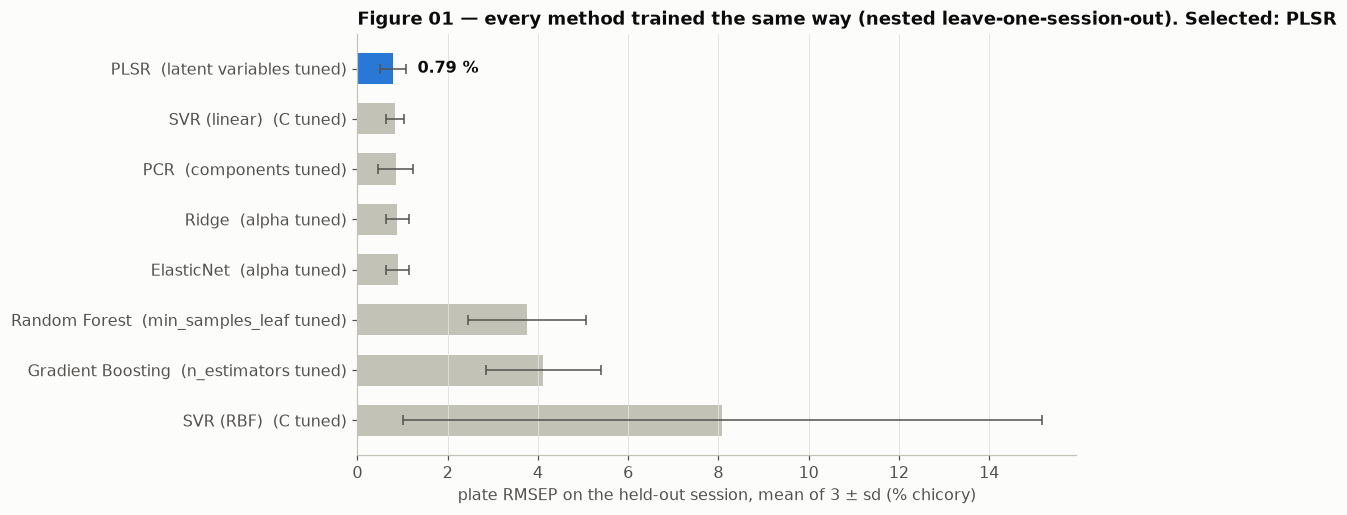

In [7]:
# Figure 01 -- the comparison that picks the method
order = SUMMARY.index.tolist()
fig, ax = plt.subplots(figsize=(10, 4.8))
v, e = SUMMARY.loc[order, "mean_rmsep"].to_numpy(), SUMMARY.loc[order, "sd_rmsep"].to_numpy()
ax.barh(np.arange(len(order)), v, height=.62, color=[HIGHLIGHT if m == SELECTED else OTHER for m in order],
        xerr=e, error_kw=dict(ecolor=INK2, elinewidth=1, capsize=3))
i = order.index(SELECTED)
ax.text(v[i] + e[i], i, f"  {v[i]:.2f} %", va="center", color=INK, fontweight="bold")
ax.set_yticks(np.arange(len(order)), [f"{m}  ({PARAM[m]} tuned)" for m in order])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("plate RMSEP on the held-out session, mean of 3 ± sd (% chicory)")
ax.set_title(f"Figure 01 — every method trained the same way (nested leave-one-session-out). Selected: {SELECTED}",
             loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "01_method_comparison.png", bbox_inches="tight"); plt.show()

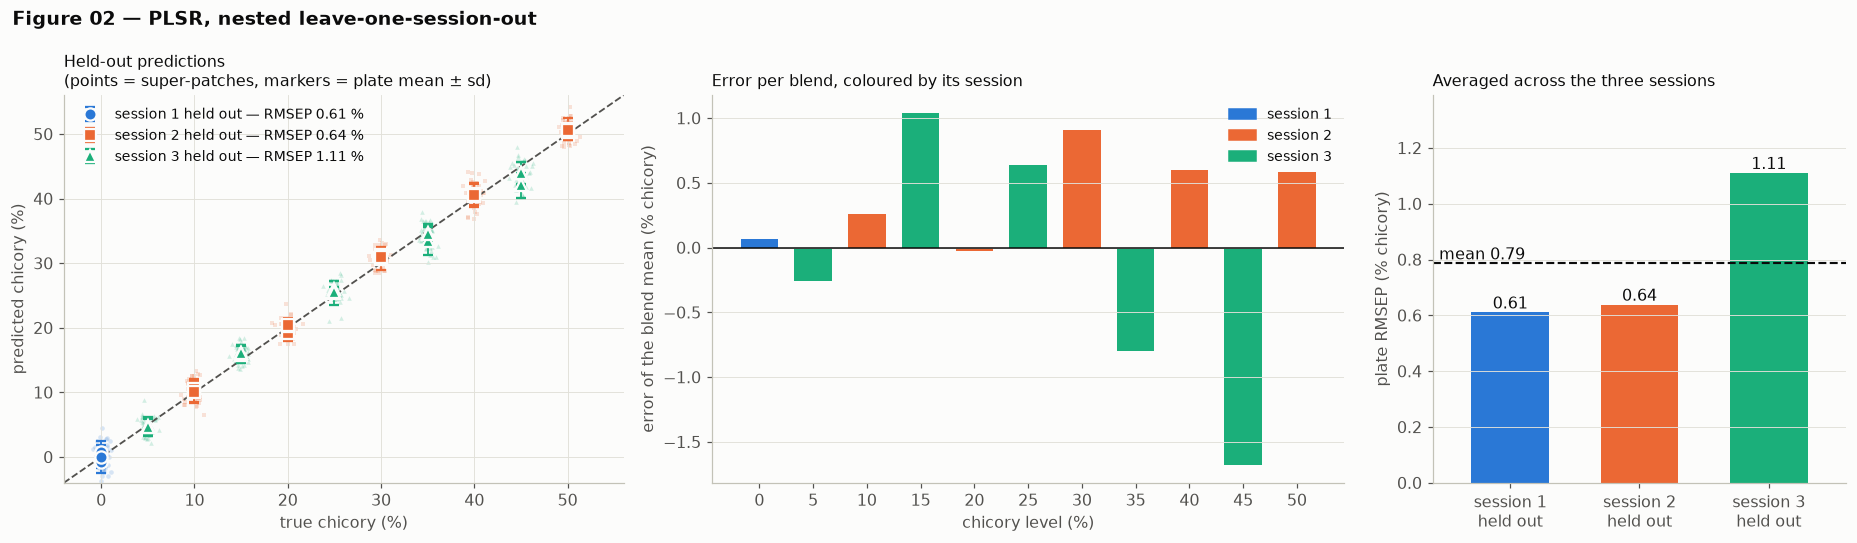

In [8]:
# Figure 02 -- selected method, each session predicted by a model that never saw it
sel = PRED[PRED.model == SELECTED]
pl  = sel.groupby(["fold", "group", "y"], as_index=False).agg(p=("p", "mean"), sd=("p", "std"))
smp = sel.groupby(["fold", "label", "y"], as_index=False)["p"].mean().sort_values("y")
smp["err"] = smp.p - smp.y
LIM = [-4, 56]

fig, axs = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw=dict(width_ratios=[1.15, 1.3, .85]))
ax = axs[0]
for s in (1, 2, 3):
    u, q = sel[sel.fold == s], pl[pl.fold == s]
    ax.scatter(u.y + RNG.normal(0, .5, len(u)), u.p, s=9, alpha=.18, color=S_COLOR[s], marker=S_MARKER[s], lw=0)
    ax.errorbar(q.y, q.p, yerr=q.sd, fmt=S_MARKER[s], ms=8, color=S_COLOR[s], mec=SURFACE, mew=1.5,
                ecolor=S_COLOR[s], elinewidth=1.2, capsize=3, zorder=4,
                label=f"session {s} held out — RMSEP {FR.loc[s, 'rmsep_plate']:.2f} %")
ax.plot(LIM, LIM, ls="--", color=INK2, lw=1.2, zorder=1)
ax.set_xlim(LIM); ax.set_ylim(LIM)
ax.set_xlabel("true chicory (%)"); ax.set_ylabel("predicted chicory (%)")
ax.set_title("Held-out predictions\n(points = super-patches, markers = plate mean ± sd)", loc="left", fontsize=10.5)
ax.legend(loc="upper left")

ax = axs[1]
ax.bar(np.arange(len(smp)), smp.err, width=.7, color=[S_COLOR[s] for s in smp.fold])
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(np.arange(len(smp)), [f"{v:.0f}" for v in smp.y])
ax.set_xlabel("chicory level (%)"); ax.set_ylabel("error of the blend mean (% chicory)")
ax.set_title("Error per blend, coloured by its session", loc="left", fontsize=10.5)
ax.legend(handles=[Patch(color=S_COLOR[s], label=f"session {s}") for s in (1, 2, 3)], loc="best")
ax.grid(axis="x", visible=False)

ax = axs[2]
vals = [FR.loc[s, "rmsep_plate"] for s in (1, 2, 3)]
ax.bar([1, 2, 3], vals, width=.6, color=[S_COLOR[s] for s in (1, 2, 3)])
for s, val in zip((1, 2, 3), vals):
    ax.text(s, val, f"{val:.2f}", ha="center", va="bottom", color=INK)
mv = SUMMARY.loc[SELECTED, "mean_rmsep"]
ax.axhline(mv, color=INK, ls="--", lw=1.4)
ax.text(.45, mv, f"mean {mv:.2f}", va="bottom", color=INK)
ax.set_xlim(.4, 3.6); ax.set_ylim(0, max(vals) * 1.25)
ax.set_xticks([1, 2, 3], [f"session {s}\nheld out" for s in (1, 2, 3)])
ax.set_ylabel("plate RMSEP (% chicory)")
ax.set_title("Averaged across the three sessions", loc="left", fontsize=10.5)
ax.grid(axis="x", visible=False)
fig.suptitle(f"Figure 02 — {SELECTED}, nested leave-one-session-out", x=.01, ha="left", fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "02_selected_loso.png", bbox_inches="tight"); plt.show()

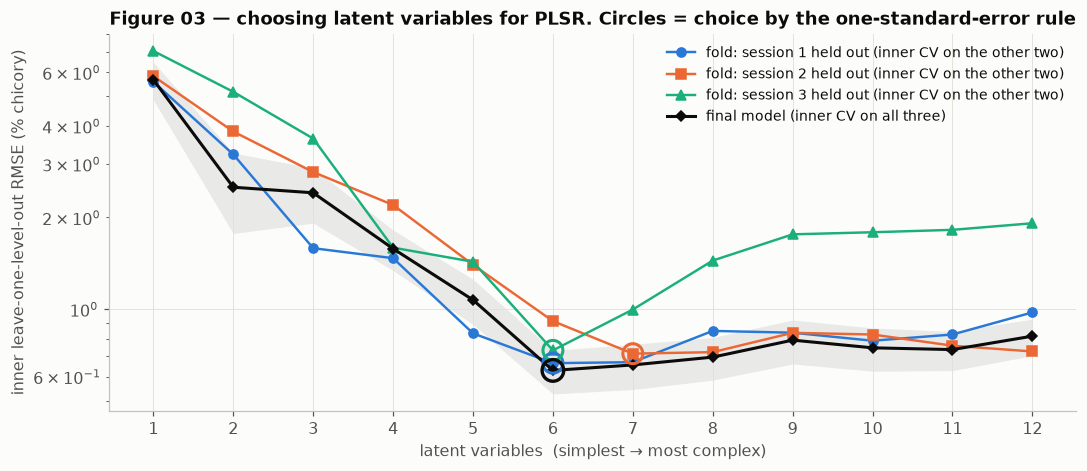

In [9]:
# Figure 03 -- how the hyperparameter was chosen, in every fold and for the final model
tl = TUNE_LOG[TUNE_LOG.model == SELECTED]
grid = GRIDS[SELECTED]
x = np.arange(len(grid))
fig, ax = plt.subplots(figsize=(10, 4.4))
for s in (1, 2, 3):
    t = tl[tl.outer == s].reset_index(drop=True)
    ax.plot(x, t["mean"], color=S_COLOR[s], marker=S_MARKER[s], ms=6, lw=1.6,
            label=f"fold: session {s} held out (inner CV on the other two)")
    c = int(np.flatnonzero(t.chosen)[0])
    ax.scatter(x[c], t["mean"][c], s=170, facecolor="none", edgecolor=S_COLOR[s], lw=2, zorder=5)
ft = FINAL_TUNE.reset_index(drop=True)
ax.plot(x, ft["mean"], color=INK, lw=2, marker="D", ms=5, label="final model (inner CV on all three)")
ax.fill_between(x, ft["mean"] - ft["se"], ft["mean"] + ft["se"], color=INK, alpha=.08, lw=0)
c = int(np.flatnonzero(ft.chosen)[0])
ax.scatter(x[c], ft["mean"][c], s=200, facecolor="none", edgecolor=INK, lw=2.2, zorder=6)
ax.set_xticks(x, [str(p) for p in grid])
ax.set_xlabel(f"{PARAM[SELECTED]}  (simplest → most complex)")
ax.set_ylabel("inner leave-one-level-out RMSE (% chicory)")
ax.set_yscale("log")
ax.set_title(f"Figure 03 — choosing {PARAM[SELECTED]} for {SELECTED}. Circles = choice by the one-standard-error rule",
             loc="left", fontsize=11.5, fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(OUT / "03_tuning_selected.png", bbox_inches="tight"); plt.show()

12 most influential wavelengths (nm): [1704 1710 1715 1721 1726 1732 1737 1743 1748 1753 1759 1764]


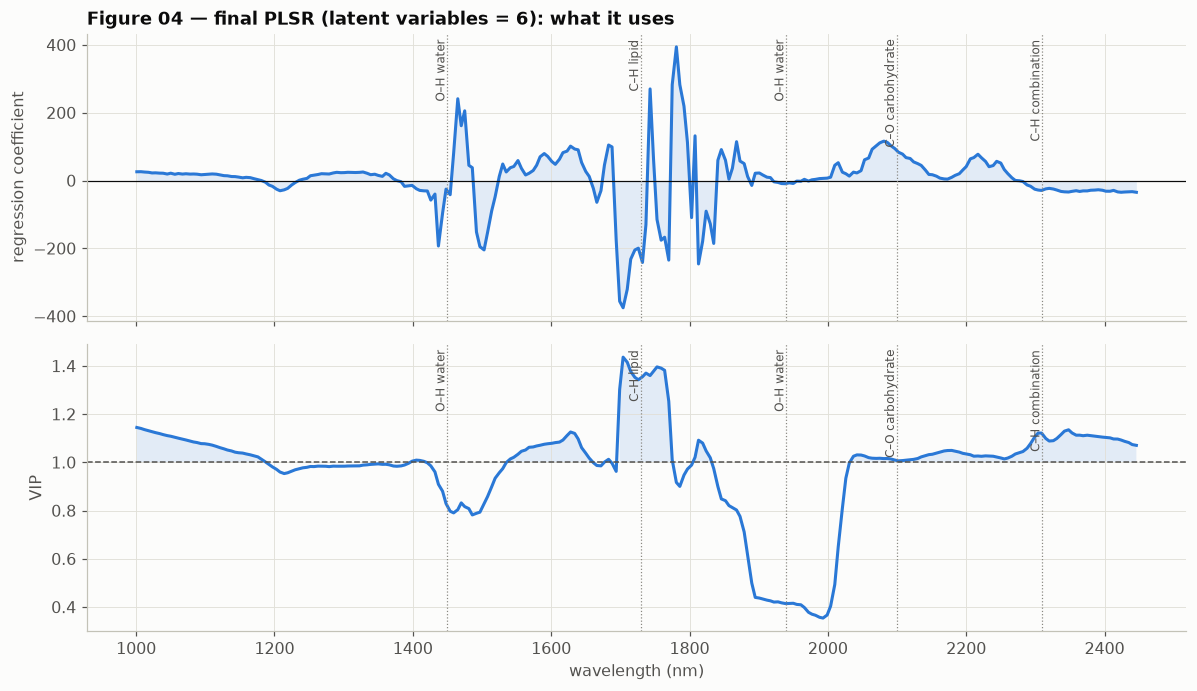

In [10]:
# Figure 04 -- what the final model uses
coef = linear_coef(FINAL)
if coef is None:
    print(f"{SELECTED} has no linear coefficients -- figure 04 skipped")
else:
    has_vip = isinstance(FINAL, PLSRegression)
    fig, axs = plt.subplots(2 if has_vip else 1, 1, figsize=(11, 6.4 if has_vip else 3.8), sharex=True, squeeze=False)
    ax = axs[0][0]
    ax.fill_between(WL, 0, coef, color=HIGHLIGHT, alpha=.12, lw=0)
    ax.plot(WL, coef, color=HIGHLIGHT, lw=2)
    ax.axhline(0, color=INK, lw=.8); ax.set_ylabel("regression coefficient")
    ax.set_title(f"Figure 04 — final {SELECTED} ({PARAM[SELECTED]} = {FINAL_PARAM}): what it uses",
                 loc="left", fontsize=12, fontweight="bold")
    if has_vip:
        W_, T_, Q_ = FINAL.x_weights_, FINAL.x_scores_, FINAL.y_loadings_.ravel()
        ss = (Q_ ** 2) * (T_ ** 2).sum(0)
        vip = np.sqrt(WL.size * ((W_ ** 2 / (W_ ** 2).sum(0)) @ ss) / ss.sum())
        ax2 = axs[1][0]
        ax2.plot(WL, vip, color=HIGHLIGHT, lw=2)
        ax2.axhline(1, color=INK2, ls="--", lw=1)
        ax2.fill_between(WL, 1, vip, where=vip > 1, color=HIGHLIGHT, alpha=.12, lw=0)
        ax2.set_ylabel("VIP")
        print("12 most influential wavelengths (nm):", np.sort(WL[np.argsort(-vip)[:12]]).astype(int))
    for a in axs.ravel():
        for nm, t in BANDS:
            a.axvline(nm, color=MUTED, lw=.8, ls=":")
            a.text(nm, .98, t, transform=a.get_xaxis_transform(), rotation=90, va="top", ha="right",
                   fontsize=8, color=INK2)
    axs[-1][0].set_xlabel("wavelength (nm)")
    plt.tight_layout(); plt.savefig(OUT / "04_final_model_coefficients.png", bbox_inches="tight"); plt.show()

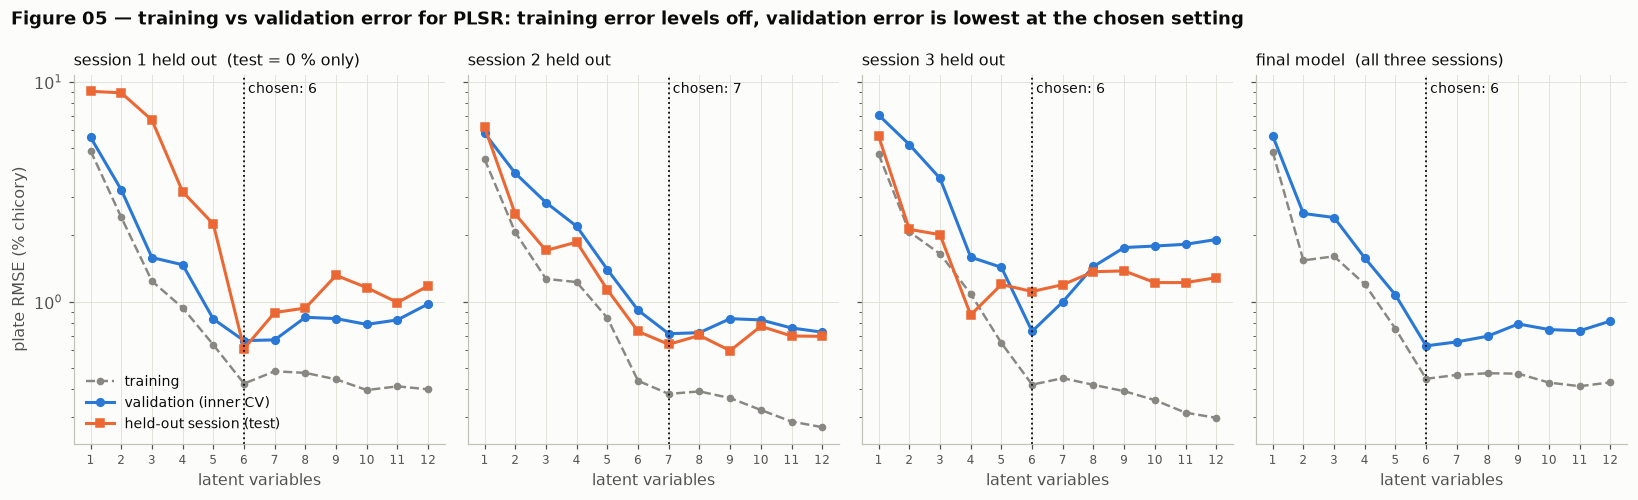

at the chosen latent variables (plate RMSE, % chicory):
       param  training  validation  held_out
fold                                        
1          6      0.42        0.66      0.61
2          7      0.38        0.71      0.64
3          6      0.42        0.73      1.11
final      6      0.45        0.63       NaN


In [11]:
# Figure 05 -- training vs validation error against model complexity (the PLS equivalent of a loss curve)
# training   = error on the plates the model was fitted on (always falls as complexity grows)
# validation = inner leave-one-concentration-out error, the curve the setting was chosen on (as in figure 03)
# held-out   = error on the session the fold never saw (the reported test error)
# training and validation are averaged per concentration level, the same way tune() scores them
def level_rmse(y, p, g):
    return float(np.mean([plate_rmse(y[y == v], p[y == v], g[y == v]) for v in np.unique(y)]))

grid = GRIDS[SELECTED]
x = np.arange(len(grid))
rows = []
for held in (1, 2, 3, None):
    train = [s for s in (1, 2, 3) if s != held]
    ZU, UM = units(train)
    us, y, g = UM.session.to_numpy(), UM.chicory_pct.to_numpy(float), UM.group.to_numpy()
    tr, te = np.isin(us, train), us == held
    cv = FINAL_TUNE if held is None else TUNE_LOG[(TUNE_LOG.model == SELECTED) & (TUNE_LOG.outer == held)]
    cv = cv.reset_index(drop=True)
    for i, prm in enumerate(grid):
        m = make(SELECTED, prm).fit(ZU[tr], y[tr])
        rows.append(dict(fold="final" if held is None else held, param=prm,
                         training=level_rmse(y[tr], predict(m, ZU[tr]), g[tr]),
                         validation=float(cv.loc[i, "mean"]),
                         held_out=plate_rmse(y[te], predict(m, ZU[te]), g[te]) if te.any() else np.nan,
                         chosen=bool(cv.loc[i, "chosen"])))
CURVE = pd.DataFrame(rows)
CURVE.to_csv(OUT / "training_validation_curve.csv", index=False)

panels = [(1, "session 1 held out  (test = 0 % only)"), (2, "session 2 held out"),
          (3, "session 3 held out"), ("final", "final model  (all three sessions)")]
fig, axs = plt.subplots(1, 4, figsize=(15, 4.6), sharey=True)
for ax, (f, title) in zip(axs, panels):
    c = CURVE[CURVE.fold == f].reset_index(drop=True)
    k = int(np.flatnonzero(c.chosen)[0])
    ax.plot(x, c.training, color=MUTED, ls="--", marker="o", ms=4, lw=1.6, label="training")
    ax.plot(x, c.validation, color=HIGHLIGHT, marker="o", ms=5, lw=2, label="validation (inner CV)")
    if c.held_out.notna().any():
        ax.plot(x, c.held_out, color="#eb6834", marker="s", ms=5, lw=2, label="held-out session (test)")
    ax.axvline(k, color=INK, ls=":", lw=1.2)
    ax.text(k, .98, f" chosen: {grid[k]}", transform=ax.get_xaxis_transform(), va="top", ha="left",
            fontsize=9, color=INK)
    ax.set_xticks(x, [str(p) for p in grid], fontsize=8)
    ax.set_xlabel(PARAM[SELECTED])
    ax.set_title(title, loc="left", fontsize=10.5)
axs[0].set_yscale("log")
axs[0].set_ylabel("plate RMSE (% chicory)")
axs[0].legend(loc="lower left")
fig.suptitle(f"Figure 05 — training vs validation error for {SELECTED}: training error levels off, "
             "validation error is lowest at the chosen setting", x=.01, ha="left", fontsize=11.5, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "05_training_validation_curve.png", bbox_inches="tight"); plt.show()

print(f"at the chosen {PARAM[SELECTED]} (plate RMSE, % chicory):")
print(CURVE[CURVE.chosen].set_index("fold")[["param", "training", "validation", "held_out"]].round(2).to_string())

## 8. Saving and the headline numbers

In [12]:
def clean(v):
    if isinstance(v, (float, np.floating)):
        return None if not np.isfinite(v) else round(float(v), 4)
    if isinstance(v, np.integer):
        return int(v)
    return v

OUTER.to_csv(OUT / "outer_folds_all_methods.csv", index=False)
SUMMARY.reset_index(names="model").to_csv(OUT / "method_summary.csv", index=False)
TUNE_LOG.to_csv(OUT / "inner_tuning_log.csv", index=False)
sel.to_csv(OUT / "heldout_predictions_selected.csv", index=False)

y_pl = pl.y.to_numpy()
RPD = float(np.std(y_pl, ddof=1) / SUMMARY.loc[SELECTED, "pooled_rmsep"])
summary = dict(
    data=dict(levels_pct=LEVELS_KEEP, plates=int(DATA.group.nunique()), patches=int(len(DATA)), sessions=[1, 2, 3]),
    training_method="pooled calibration; nested leave-one-session-out; inner leave-one-concentration-out "
                    "with the one-standard-error rule; trimming refitted inside each fold",
    selected=dict(method=SELECTED, param_name=PARAM[SELECTED], final_param=clean(FINAL_PARAM),
                  params_in_folds={int(s): clean(FR.loc[s, "param"]) for s in (1, 2, 3)}),
    loso=dict(per_held_out_session={int(s): {k: clean(FR.loc[s, k]) for k in
                                             ["rmsep_plate", "rmsep_sample", "bias", "r2", "slope", "intercept"]}
                                    for s in (1, 2, 3)},
              mean_rmsep=clean(SUMMARY.loc[SELECTED, "mean_rmsep"]), sd_rmsep=clean(SUMMARY.loc[SELECTED, "sd_rmsep"]),
              pooled_rmsep=clean(SUMMARY.loc[SELECTED, "pooled_rmsep"]),
              pooled_r2=clean(SUMMARY.loc[SELECTED, "pooled_r2"]), rpd=round(RPD, 2)),
    runner_up=dict(method=RUNNER_UP, mean_rmsep=clean(SUMMARY.loc[RUNNER_UP, "mean_rmsep"]),
                   difference_ci95=[clean(DIFF_CI[0]), clean(DIFF_CI[1])], tie=TIE),
    all_methods=[{k: clean(v) for k, v in r.items()} for r in SUMMARY.reset_index(names="model").to_dict("records")],
)
(OUT / "summary.json").write_text(json.dumps(summary, indent=2))

print("=" * 72)
print(f"SELECTED: {SELECTED}   final {PARAM[SELECTED]} = {FINAL_PARAM}")
print("=" * 72)
for s in (1, 2, 3):
    r = FR.loc[s]
    extra = "" if np.isnan(r.r2) else f"   R² {r.r2:.3f}   slope {r.slope:.3f}"
    print(f"  session {s} held out  ({PARAM[SELECTED]} {r.param})   plate RMSEP {r.rmsep_plate:5.2f} %   "
          f"bias {r.bias:+5.2f}{extra}")
print(f"  mean over the 3 sessions   {SUMMARY.loc[SELECTED, 'mean_rmsep']:.2f} % (sd {SUMMARY.loc[SELECTED, 'sd_rmsep']:.2f})"
      f"   pooled {SUMMARY.loc[SELECTED, 'pooled_rmsep']:.2f} %   R² {SUMMARY.loc[SELECTED, 'pooled_r2']:.4f}   RPD {RPD:.1f}")
print(f"  vs {RUNNER_UP}: " + ("tie" if TIE else "different") + f" (CI {DIFF_CI[0]:+.2f} to {DIFF_CI[1]:+.2f})")
print("\nsaved to", OUT)

SELECTED: PLSR   final latent variables = 6
  session 1 held out  (latent variables 6.0)   plate RMSEP  0.61 %   bias +0.04
  session 2 held out  (latent variables 7.0)   plate RMSEP  0.64 %   bias +0.47   R² 0.998   slope 1.013
  session 3 held out  (latent variables 6.0)   plate RMSEP  1.11 %   bias -0.21   R² 0.994   slope 0.953
  mean over the 3 sessions   0.79 % (sd 0.28)   pooled 0.88 %   R² 0.9969   RPD 18.2
  vs SVR (linear): tie (CI -0.14 to +0.05)

saved to /run/media/riyanvarghese/RIYAN HDD/coffee data/final_regression


## 9. Why this training method suits data from separate acquisitions

**The data is nested, and errors are shared at every level.** A super-patch belongs to a plate, a plate is one
stir of one weighed blend, and every blend was scanned in one session. Two super-patches from the same plate
share packing; three stirs of a blend share the weighing; all plates in a session share the day's lamp, focus,
sample height and calibration strip. A split is only honest at the level where the test data is new in every
one of those respects — here that's the **session**.

**What the alternatives would have reported:**

| split | what leaks into training | effect |
|---|---|---|
| random patches or super-patches | neighbours from the same plate | near-perfect R², meaningless |
| by plate (grouped k-fold) | the other two stirs of the same powder | still flattering |
| leave-one-concentration-out | the session the held-out level came from | honest about concentration, silent about session drift |
| one model per session, averaged | — | session 1 can't be trained (one level); each model sees a narrow range and no session variation |
| **leave-one-session-out** | nothing from the held-out acquisition | the error a new day would actually produce |

**Pooling** the sessions in training is what lets the model learn to ignore acquisition differences; leave-one-
session-out measures whether it did. Per-session models can't learn that at all.

**Nesting** matters because hyperparameters are chosen by looking at errors. If the number of latent variables
were picked on all the data and then scored by leave-one-session-out — as in the earlier notebooks — the held-out
session would already have influenced the choice. Here it never does, so the reported error is genuinely out of
sample.

**The one-standard-error rule** favours the simplest adequate model. Earlier work on this data showed session
bias growing with the number of latent variables, so between two settings the data can't tell apart, the simpler
one is the safer bet for a new acquisition.

**Same procedure for every method** — same folds, same preprocessing, same tuning rule — so the comparison
reflects the methods, not the bookkeeping.

**Limits it can't remove.** Each concentration was scanned in only one session, so every outer fold tests a
session change and a concentration gap at once; the session-1 fold checks 0 % only. Three sessions give three
outer folds, so the mean error itself carries real uncertainty — quote it with its sd. Repeating a few existing
blends in a future session is what would separate the two effects.